# Part 6: Richer Features and a Sequence Model on the ML Side

### Ramith Vaid | NTU Singapore

Part 4 compared GARCH(1,1) with the Part 1 machine learning model across ten assets. The ML side there was deliberately the Part 1 model: Gradient Boosting on 12 lagged return and volatility features. That leaves an obvious objection: a better-built ML model might change the ranking. This part asks whether a better ML setup changes the ranking against GARCH, using the same leakage-checked design as Part 4: the aligned forward 21-day target, features that use data through day t only (re-checked below with a truncation test), one model per block trained only on rows whose forward window ends before the block starts, three non-overlapping 250-day blocks per asset, and the same scored days as Part 4 so the GARCH and naive forecasts are directly comparable.

**Models.**
- *GARCH(1,1)* and the *naive* trailing-volatility forecast, taken from Part 4.
- *HAR*: ordinary least squares on realized volatility over 5, 21 and 63 days (the three-horizon heterogeneous autoregressive regression, a standard strong baseline for realized volatility).
- *GBR base*: Part 1's model and features (Gradient Boosting, 12 features), re-fit on this part's feature table.
- *GBR rich*: the same Gradient Boosting on a larger feature set, added in three groups so each group's contribution can be seen: the HAR horizons, downside and upside semivolatility plus the largest absolute return in 21 days, and high-low range volatility (which uses the intraday range, not just closes).
- *GBR rich + VIX*: the rich set plus the VIX level and its 5-day change (known at the close of day t).
- *Ridge on the rich set*, standardized features.
- *GRU*: a single-layer gated recurrent network over the last 42 days of daily return, absolute return, log high-low range and VIX, with a linear read-out. PyTorch is not available for this Python build, so it is implemented in numpy (`NumpyGRU` in `garch_utils.py`, trained with Adam and backpropagation through time; its gradients were checked against finite differences). Each block's forecast is the average of three seeds; the last 15% of the training sequences are held out for early stopping.

Six assets: JPM, the S&P 500, Apple, Exxon, emerging-market equities and gold, so VIX is a natural feature for most but not all of them. Data end date pinned to 2026-10-13.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

from garch_utils import (
    build_rich_features, FEATURE_SETS, NumpyGRU, make_sequences, make_blocks, ml_block_forecast, default_gbr,
    score_forecasts, dm_test
)
print('Libraries loaded.')

Libraries loaded.


## 1. Data

In [2]:
TICKERS = {'JPM': 'US equity', '^GSPC': 'US equity index', 'AAPL': 'US equity', 'XOM': 'US equity',
           'EEM': 'International equity ETF', 'GLD': 'Commodity ETF'}
START, END = '2014-01-01', '2026-10-14'  # END is exclusive: last row is 2026-10-13
ohlc = {}
for tk in TICKERS:
    d = yf.download(tk, start=START, end=END, progress=False)
    d.columns = [c[0] for c in d.columns]
    ohlc[tk] = d[['Open', 'High', 'Low', 'Close']].dropna()
vix = yf.download('^VIX', start=START, end=END, progress=False)['Close'].squeeze().dropna()
print({tk: len(d) for tk, d in ohlc.items()}, '| VIX rows:', len(vix))

part4 = pd.read_csv('part4_forecasts.csv', parse_dates=['date'], index_col='date')
print('Part 4 forecasts loaded:', sorted(part4['ticker'].unique()))

{'JPM': 3214, '^GSPC': 3214, 'AAPL': 3214, 'XOM': 3214, 'EEM': 3214, 'GLD': 3214} | VIX rows: 3216
Part 4 forecasts loaded: ['AAPL', 'BTC-USD', 'EEM', 'EURUSD=X', 'GLD', 'JPM', 'TLT', 'VNQ', 'XOM', '^GSPC']


## 2. Leakage check

A truncation test per asset: the feature row for day t computed from data cut off at day t (prices, highs, lows and VIX) must equal the same row computed from the full history. This catches any feature that reaches forward, including the range and VIX features and the rolling windows.

In [3]:
def truncation_check(tk, n_checks=6, seed=0):
    feat, processed = build_rich_features(ohlc[tk], vix=vix)
    cols = FEATURE_SETS['rich_vix']
    rng = np.random.default_rng(seed)
    ok = True
    for p in rng.integers(300, len(processed) - 30, n_checks):
        d = processed.index[p]
        o = ohlc[tk].loc[:d]
        f2, _ = build_rich_features(o, vix=vix.loc[:d])
        if d in f2.index and d in feat.index:
            ok &= bool(np.allclose(f2.loc[d, cols].values.astype(float), feat.loc[d, cols].values.astype(float)))
    return ok
print('Feature rows at day t use only data through day t:', {tk: truncation_check(tk) for tk in TICKERS})

Feature rows at day t use only data through day t: {'JPM': True, '^GSPC': True, 'AAPL': True, 'XOM': True, 'EEM': True, 'GLD': True}


## 3. Forecasts, three blocks per asset

For each asset and block: HAR, the three Gradient Boosting variants, Ridge and the GRU, all trained on rows that end at least 22 days before the block starts. The Part 4 GARCH, GBR (Part 1 features, original feature table) and naive forecasts are carried in for the same days. The GRU takes a few minutes per asset.

In [4]:
def gru_forecast(feat, processed, ohlc_tk, positions, embargo=22, window=42, seeds=(0, 1, 2)):
    ch = pd.DataFrame(index=processed.index)
    r = processed['log_return']
    ch['ret'] = r * 100
    ch['abs'] = r.abs() * 100
    ch['hl'] = np.log(ohlc_tk['High'] / ohlc_tk['Low']).reindex(processed.index) * 100
    ch['vix'] = np.log(vix.reindex(processed.index).ffill())
    ch = ch.ffill().bfill()
    X_all, kept = make_sequences(ch, feat, processed, window)
    kept_pos = processed.index.get_indexer(kept)
    y_all = feat.loc[kept, 'target_vol'].values
    tr = kept_pos <= positions[0] - embargo
    Xtr, ytr = X_all[tr], y_all[tr]
    mu, sd = Xtr.reshape(-1, Xtr.shape[2]).mean(0), Xtr.reshape(-1, Xtr.shape[2]).std(0) + 1e-9
    ym, ys = ytr.mean(), ytr.std()
    Xn = (X_all - mu) / sd
    cut = int(len(Xtr) * 0.85)
    preds = []
    for s in seeds:
        net = NumpyGRU(Xn.shape[2], 16, seed=s)
        net.fit(Xn[tr][:cut], (ytr[:cut] - ym) / ys, Xn[tr][cut:], (ytr[cut:] - ym) / ys, epochs=40, seed=s)
        pos_idx = [list(kept).index(processed.index[p]) for p in positions]
        preds.append(net.predict(Xn[pos_idx]) * ys + ym)
    return np.mean(preds, axis=0)

N_BLOCKS, BLOCK_LEN = 3, 250
rows = []
importances = {}
for tk in TICKERS:
    feat, processed = build_rich_features(ohlc[tk], vix=vix)
    blocks = make_blocks(len(processed), N_BLOCKS, BLOCK_LEN)
    row_pos = processed.index.get_indexer(feat.index)
    for label, pos in blocks.items():
        dates = processed.index[pos]
        out = pd.DataFrame({'ticker': tk, 'block': label, 'actual': feat.loc[dates, 'target_vol'].values}, index=dates)
        out['naive'] = processed.loc[dates, 'realized_vol'].values
        # HAR, GBR and Ridge variants share the training rows
        train = feat[row_pos <= pos[0] - 22]
        Xte = feat.loc[dates]
        out['har'] = LinearRegression().fit(train[FEATURE_SETS['har']], train['target_vol']).predict(Xte[FEATURE_SETS['har']])
        for name, cols in (('gbr_base', FEATURE_SETS['base']),
                           ('gbr_base_har', FEATURE_SETS['base'] + FEATURE_SETS['har']),
                           ('gbr_rich', FEATURE_SETS['rich']),
                           ('gbr_rich_vix', FEATURE_SETS['rich_vix'])):
            m = default_gbr().fit(train[cols], train['target_vol'])
            out[name] = m.predict(Xte[cols])
            if name == 'gbr_rich_vix':
                importances.setdefault(tk, []).append(pd.Series(m.feature_importances_, index=cols))
        sc = StandardScaler().fit(train[FEATURE_SETS['rich']])
        out['ridge_rich'] = Ridge(alpha=10.0).fit(sc.transform(train[FEATURE_SETS['rich']]), train['target_vol']).predict(sc.transform(Xte[FEATURE_SETS['rich']]))
        out['gru'] = gru_forecast(feat, processed, ohlc[tk], pos)
        p4 = part4[(part4.ticker == tk) & (part4.block == label)]
        out['garch'] = p4['garch'].reindex(dates).values
        rows.append(out)
    print(f'{tk}: done')
fc = pd.concat(rows)
fc.index.name = 'date'
print('Scored days per asset:', fc.groupby('ticker').size().to_dict())
print('Days missing a Part 4 GARCH forecast:', int(fc['garch'].isna().sum()))

JPM: done


^GSPC: done


AAPL: done


XOM: done


EEM: done


GLD: done
Scored days per asset: {'AAPL': 750, 'EEM': 750, 'GLD': 750, 'JPM': 750, 'XOM': 750, '^GSPC': 750}
Days missing a Part 4 GARCH forecast: 0


## 4. RMSE by model

Pooled over the 750 scored days of each asset (annualized percentage points), with each model's RMSE as a ratio to GARCH's. Ratios below 1 mean the model beat GARCH on that asset.

In [5]:
MODELS = ['garch', 'naive', 'har', 'gbr_base', 'gbr_base_har', 'gbr_rich', 'gbr_rich_vix', 'ridge_rich', 'gru']
rows = []
for tk, g in fc.groupby('ticker', sort=False):
    row = {'ticker': tk, 'mean_target': g['actual'].mean()}
    for m in MODELS:
        row[f'{m}'] = score_forecasts(g['actual'], g[m])['rmse']
    rows.append(row)
rm = pd.DataFrame(rows).set_index('ticker')
ratio = rm[MODELS].div(rm['garch'], axis=0)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
pd.set_option('display.width', 220)
print('RMSE (annualized pp):')
print(rm.to_string())
print()
print('RMSE relative to GARCH (below 1 = beats GARCH):')
print(ratio.to_string())
print()
print('Mean ratio across the six assets:')
print(ratio.mean().round(3).to_string())

RMSE (annualized pp):
        mean_target  garch  naive    har  gbr_base  gbr_base_har  gbr_rich  gbr_rich_vix  ridge_rich   gru
ticker                                                                                                    
JPM          21.675  8.363 10.453  8.728     9.231        10.448    10.834        12.018       8.493 8.259
^GSPC        13.494  7.280  8.061  6.549     8.445         8.108     8.245         8.539       6.355 6.216
AAPL         24.541 11.371 12.997 10.663    10.533        10.945    11.218        11.422      10.382 9.931
XOM          22.644  6.857  7.267  6.320     6.896         7.180     7.777         7.648       6.530 6.142
EEM          18.474  7.237  7.732  6.836     7.610         7.577     7.910         8.309       6.862 6.992
GLD          19.694  8.794  9.870  8.958     8.714         9.164     8.958         9.897       8.195 9.497

RMSE relative to GARCH (below 1 = beats GARCH):
        garch  naive   har  gbr_base  gbr_base_har  gbr_rich  gbr_rich_vi

## 5. Block by block, and Diebold-Mariano tests

Of the 18 asset-blocks, how often each model has the lowest RMSE, and pooled Diebold-Mariano tests (Newey-West, 20 lags) of each model against GARCH and against the Part 1 Gradient Boosting model. A negative statistic means the first model has the lower squared error.

In [6]:
rows = []
for (tk, block), g in fc.groupby(['ticker', 'block'], sort=False):
    rm_ = {m: score_forecasts(g['actual'], g[m])['rmse'] for m in MODELS}
    rm_.update({'ticker': tk, 'block': block, 'best': min(MODELS, key=lambda m: rm_[m])})
    rows.append(rm_)
byblock = pd.DataFrame(rows)
print('Lowest RMSE per asset-block (of', len(byblock), '):', byblock['best'].value_counts().to_dict())
print('Models beating GARCH in more than half of the asset-blocks:',
      {m: int((byblock[m] < byblock['garch']).sum()) for m in MODELS if m != 'garch'})
print()
rows = []
for tk, g in fc.groupby('ticker', sort=False):
    for m in MODELS:
        if m in ('garch',):
            continue
        s, p = dm_test((g[m] - g['actual']) ** 2, (g['garch'] - g['actual']) ** 2, 20)
        s2, p2 = (dm_test((g[m] - g['actual']) ** 2, (g['gbr_base'] - g['actual']) ** 2, 20) if m != 'gbr_base' else (np.nan, np.nan))
        rows.append({'ticker': tk, 'model': m, 'dm_vs_garch': s, 'p_vs_garch': p, 'dm_vs_gbr_base': s2, 'p_vs_gbr_base': p2})
dmt = pd.DataFrame(rows)
print(dmt.pivot(index='ticker', columns='model', values='p_vs_garch').round(3).to_string())
print()
print('Models significantly better than GARCH (p < 0.05, negative statistic):',
      dmt[(dmt.p_vs_garch < 0.05) & (dmt.dm_vs_garch < 0)][['ticker', 'model']].values.tolist())
print('Models significantly worse than GARCH (p < 0.05, positive statistic):',
      dmt[(dmt.p_vs_garch < 0.05) & (dmt.dm_vs_garch > 0)][['ticker', 'model']].values.tolist())

Lowest RMSE per asset-block (of 18 ): {'gru': 6, 'garch': 3, 'ridge_rich': 3, 'har': 2, 'gbr_base_har': 2, 'gbr_rich': 1, 'gbr_rich_vix': 1}
Models beating GARCH in more than half of the asset-blocks: {'naive': 3, 'har': 9, 'gbr_base': 5, 'gbr_base_har': 6, 'gbr_rich': 7, 'gbr_rich_vix': 4, 'ridge_rich': 11, 'gru': 11}

model   gbr_base  gbr_base_har  gbr_rich  gbr_rich_vix   gru   har  naive  ridge_rich
ticker                                                                               
AAPL       0.207         0.462     0.858         0.955 0.135 0.244  0.120       0.122
EEM        0.420         0.446     0.297         0.224 0.534 0.120  0.555       0.329
GLD        0.871         0.427     0.730         0.054 0.171 0.712  0.073       0.322
JPM        0.205         0.031     0.063         0.113 0.803 0.284  0.145       0.804
XOM        0.923         0.559     0.436         0.523 0.062 0.025  0.523       0.247
^GSPC      0.371         0.492     0.455         0.342 0.199 0.239  0.229   

## 6. Which features carry the signal?

Gradient Boosting feature importance for the rich + VIX model, averaged over blocks and assets, and the ablation of feature groups from the table in section 4 (base, base plus the HAR horizons, rich, rich plus VIX).

In [7]:
imp = pd.concat([pd.concat(v, axis=1).mean(axis=1) for v in importances.values()], axis=1).mean(axis=1).sort_values(ascending=False)
print((imp * 100).round(1).head(12).to_string())
print()
print('Mean RMSE ratio to GARCH, by feature set (Gradient Boosting):')
print(ratio[['gbr_base', 'gbr_base_har', 'gbr_rich', 'gbr_rich_vix']].mean().round(3).to_string())

vix                  25.200
max_abs_ret21        10.800
rv63                 10.700
range_vol21           9.700
return_abs_5d_mean    7.200
semi_down21           6.800
semi_up21             6.500
range_vol5            6.200
vix_chg5              3.400
vol_lag_1             2.500
rv21                  2.100
vol_lag_5             1.800

Mean RMSE ratio to GARCH, by feature set (Gradient Boosting):
gbr_base       1.040
gbr_base_har   1.077
gbr_rich       1.110
gbr_rich_vix   1.167


## 7. Chart

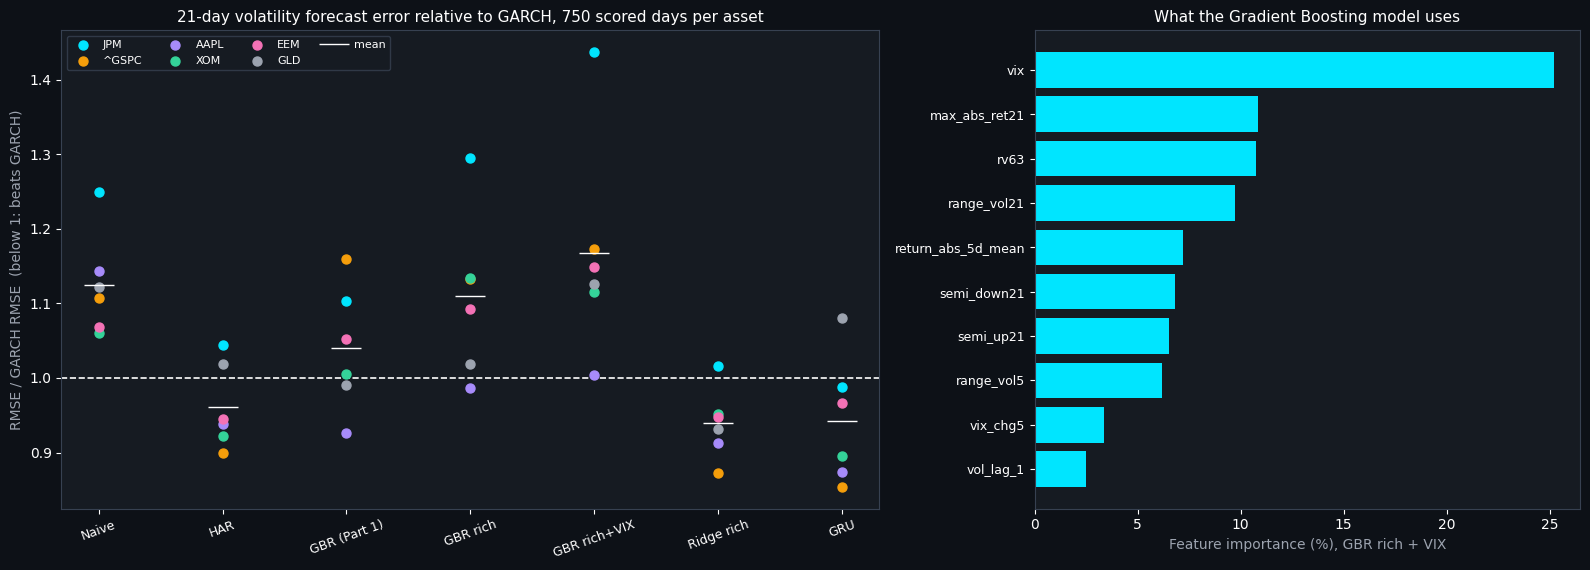

Saved chart_part6_ml_variants.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), gridspec_kw={'width_ratios': [1.5, 1]})
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#374151')
ax = axes[0]
show = ['naive', 'har', 'gbr_base', 'gbr_rich', 'gbr_rich_vix', 'ridge_rich', 'gru']
names = {'naive': 'Naive', 'har': 'HAR', 'gbr_base': 'GBR (Part 1)', 'gbr_rich': 'GBR rich', 'gbr_rich_vix': 'GBR rich+VIX', 'ridge_rich': 'Ridge rich', 'gru': 'GRU'}
x = np.arange(len(show))
for tk, col in zip(TICKERS, ['#00e5ff', '#f59e0b', '#a78bfa', '#34d399', '#f472b6', '#9ca3af']):
    ax.scatter(x, [ratio.loc[tk, m] for m in show], color=col, s=42, label=tk, zorder=3)
ax.plot(x, [ratio[m].mean() for m in show], color='white', lw=1.4, marker='_', ms=22, ls='none', label='mean', zorder=4)
ax.axhline(1, color='white', ls='--', lw=1.2)
ax.set_xticks(x)
ax.set_xticklabels([names[m] for m in show], color='white', rotation=20, fontsize=9)
ax.set_ylabel('RMSE / GARCH RMSE  (below 1: beats GARCH)', color='#9ca3af')
ax.set_title('21-day volatility forecast error relative to GARCH, 750 scored days per asset', color='white', fontsize=11)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=8, ncol=4, loc='upper left')
ax = axes[1]
top = imp.head(10)[::-1]
ax.barh(range(len(top)), top.values * 100, color='#00e5ff')
ax.set_yticks(range(len(top)))
ax.set_yticklabels(top.index, color='white', fontsize=9)
ax.set_xlabel('Feature importance (%), GBR rich + VIX', color='#9ca3af')
ax.set_title('What the Gradient Boosting model uses', color='white', fontsize=11)
plt.tight_layout()
plt.savefig('chart_part6_ml_variants.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Saved chart_part6_ml_variants.png')

## 8. Summary and saved tables

In [9]:
fc.to_csv('part6_forecasts.csv')
rm.to_csv('part6_rmse_pooled.csv')
ratio.to_csv('part6_rmse_ratio_to_garch.csv')
byblock.to_csv('part6_by_block.csv', index=False)
dmt.to_csv('part6_dm_tests.csv', index=False)
imp.rename('importance').to_csv('part6_feature_importance.csv')
print('=' * 70)
print('PART 6 SUMMARY: ML VARIANTS')
print('=' * 70)
print(ratio.round(3).to_string())
print()
print('Files saved: chart_part6_ml_variants.png, part6_forecasts.csv, part6_rmse_pooled.csv, part6_rmse_ratio_to_garch.csv, part6_by_block.csv, part6_dm_tests.csv, part6_feature_importance.csv')

PART 6 SUMMARY: ML VARIANTS
        garch  naive   har  gbr_base  gbr_base_har  gbr_rich  gbr_rich_vix  ridge_rich   gru
ticker                                                                                      
JPM     1.000  1.250 1.044     1.104         1.249     1.295         1.437       1.015 0.988
^GSPC   1.000  1.107 0.900     1.160         1.114     1.133         1.173       0.873 0.854
AAPL    1.000  1.143 0.938     0.926         0.963     0.987         1.005       0.913 0.873
XOM     1.000  1.060 0.922     1.006         1.047     1.134         1.115       0.952 0.896
EEM     1.000  1.068 0.945     1.052         1.047     1.093         1.148       0.948 0.966
GLD     1.000  1.122 1.019     0.991         1.042     1.019         1.125       0.932 1.080

Files saved: chart_part6_ml_variants.png, part6_forecasts.csv, part6_rmse_pooled.csv, part6_rmse_ratio_to_garch.csv, part6_by_block.csv, part6_dm_tests.csv, part6_feature_importance.csv
